OUL  
This analysis is about OUL (Open University Learning) and the performance of their students in the virtual courses (VLE) offered by this university.  
The aim of this analysis is to 

In [2]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
plt.style.use('dark_background')
sns.set_palette(['#00d8ff', '#ff6600', '#aaaaaa']) 
plt.rcParams['figure.facecolor'] = '#121212'
plt.rcParams['axes.facecolor'] = '#121212'
plt.rcParams['axes.grid'] = False 
plt.rcParams['axes.edgecolor'] = '#333333'

In [4]:
df1 = pd.read_csv('studentInfo.csv')

In [5]:
df1.final_result

0               Pass
1               Pass
2          Withdrawn
3               Pass
4               Pass
            ...     
32588           Fail
32589    Distinction
32590           Pass
32591      Withdrawn
32592    Distinction
Name: final_result, Length: 32593, dtype: object

In [6]:
conexion = sqlite3.connect(':memory:')
df1.to_sql('student_db', conexion, index=False)

32593

In [7]:
print(f"The databse has {len(df1)} individual data")

The databse has 32593 individual data


In [8]:
QUERY = """
    WITH Countbygroup AS (
    SELECT 
        final_result,
        highest_education,
        COUNT(*) as total_studiants
    FROM student_db
    GROUP BY final_result, highest_education
    ),
    TotalByEducation AS (
    SELECT 
        highest_education,
        SUM(total_studiants) as total_level
    FROM Countbygroup
    GROUP BY highest_education
    )
    SELECT 
        c.final_result,
        c.highest_education,
        c.total_studiants,
        (c.total_studiants * 100.0 / t.total_level) as percentage
    FROM Countbygroup c
    JOIN TotalByEducation t ON c.highest_education = t.highest_education
    ORDER BY c.highest_education, c.final_result;
    """
df_fr = pd.read_sql_query(QUERY, conexion)
print(df_fr.head(20))

   final_result            highest_education  total_studiants  percentage
0   Distinction        A Level or Equivalent             1496   10.651477
1          Fail        A Level or Equivalent             2707   19.273763
2          Pass        A Level or Equivalent             5812   41.381274
3     Withdrawn        A Level or Equivalent             4030   28.693485
4   Distinction             HE Qualification              697   14.735729
5          Fail             HE Qualification              790   16.701903
6          Pass             HE Qualification             1960   41.437632
7     Withdrawn             HE Qualification             1283   27.124736
8   Distinction           Lower Than A Level              727    5.525156
9          Fail           Lower Than A Level             3426   26.037392
10         Pass           Lower Than A Level             4385   33.325733
11    Withdrawn           Lower Than A Level             4620   35.111719
12  Distinction              No Formal

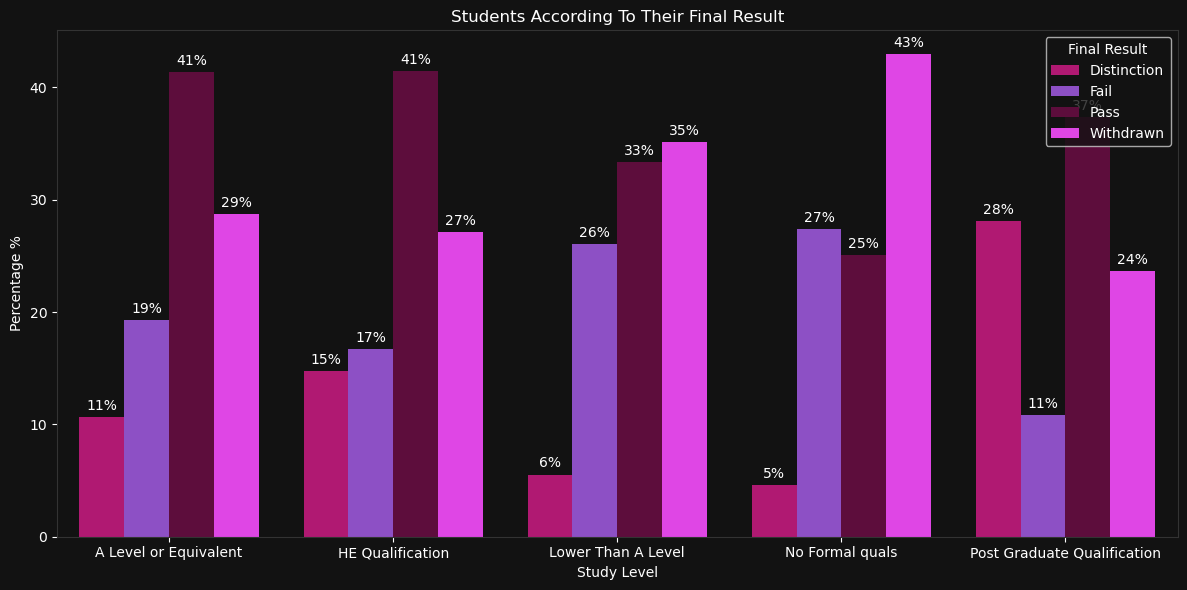

In [9]:
plt.figure(figsize=(12,6))

ax = sns.barplot(
    data=df_fr,
    x='highest_education',
    y='percentage',
    hue='final_result',
    palette=["#c90076",'#8e3cd9','#6a003e','#f72cff']
)
plt.title('Students According To Their Final Result')
plt.legend(title='Final Result')
plt.xlabel('Study Level')
plt.ylabel('Percentage %')

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f%%', padding=3, color='white')

plt.tight_layout()
plt.show()

-The students that belong to the 'A Level or Equivalent' group present a 52% overall pass rate, 11% achieved an excelent performance during the course. On the other hand, 48% of that group couldn't pass the course, the difference is just 4%, this might happen because most of the people of that group have not faced a course harder than the High School.  
-The next group, 'HE Qualification' is not very different to the first one when Fail rate or Withdrawn refers, the coincidence is that both parameters decrease just 2& respectively. So, it is possible to afirm this group have experience about studies because some of them have finished technological, techniques or undergraduate studies, that's why the performance of the people of this group is better than 'A Level or Equivalent', 'Lower Than A Level', and 'No Formal quals', even the distinction percentage is better than of the mentioned groups.  
-The next two groups, 'Lower Than A Level' and 'No Formal quals' don't have the same quantity of people, however they share almost the same percentage in Distinction and Fail, the Withdrawn percetage is the highest on those groups and if we add the value of Distinction and Pass, 'Lower Than A Level' have 39% and 'No Formal quals' 31%. The people that integrate these groups have no studies like the other groups. So, the lack of prior formal education is a key factor explaining the low success rates in these demographics.  
-The last group is 'Post Graduate Qualification' and has the highest percentage of Distinction, if we sum with Pass we'll notice that 65% finished successfully the course. This groups has also the lowest percentage of Fail and Withdrawn, this phenomenon can be explained because they have completed Post Graduate studies that give this group a lot of experience for passing academic courses. Moreover, it is necessary to consider that this group doesn't have a large amount of people like the previuos groups.

In [11]:
QUERY1 = """
    WITH Countbyage AS (
    SELECT 
        final_result,
        age_band,
        COUNT(*) as total_students
    FROM student_db
    GROUP BY final_result, age_band
    ),
    TotalByAge AS (
    SELECT 
        age_band,
        SUM(total_students) as total_age
    FROM Countbyage
    GROUP BY age_band
    )
    SELECT 
        c.final_result,
        c.age_band,
        c.total_students,
        (c.total_students * 100.0 / t.total_age) as percentage
    FROM Countbyage c
    JOIN TotalByAge t ON c.age_band = t.age_band
    ORDER BY c.age_band, c.final_result;
    """
df_ab = pd.read_sql_query(QUERY1, conexion)
print(df_ab.head(12))

   final_result age_band  total_students  percentage
0   Distinction     0-35            1863    8.119770
1          Fail     0-35            5231   22.798989
2          Pass     0-35            8469   36.911611
3     Withdrawn     0-35            7381   32.169630
4   Distinction    35-55            1120   11.873211
5          Fail    35-55            1792   18.997138
6          Pass    35-55            3800   40.284109
7     Withdrawn    35-55            2721   28.845542
8   Distinction     55<=              41   18.981481
9          Fail     55<=              29   13.425926
10         Pass     55<=              92   42.592593
11    Withdrawn     55<=              54   25.000000


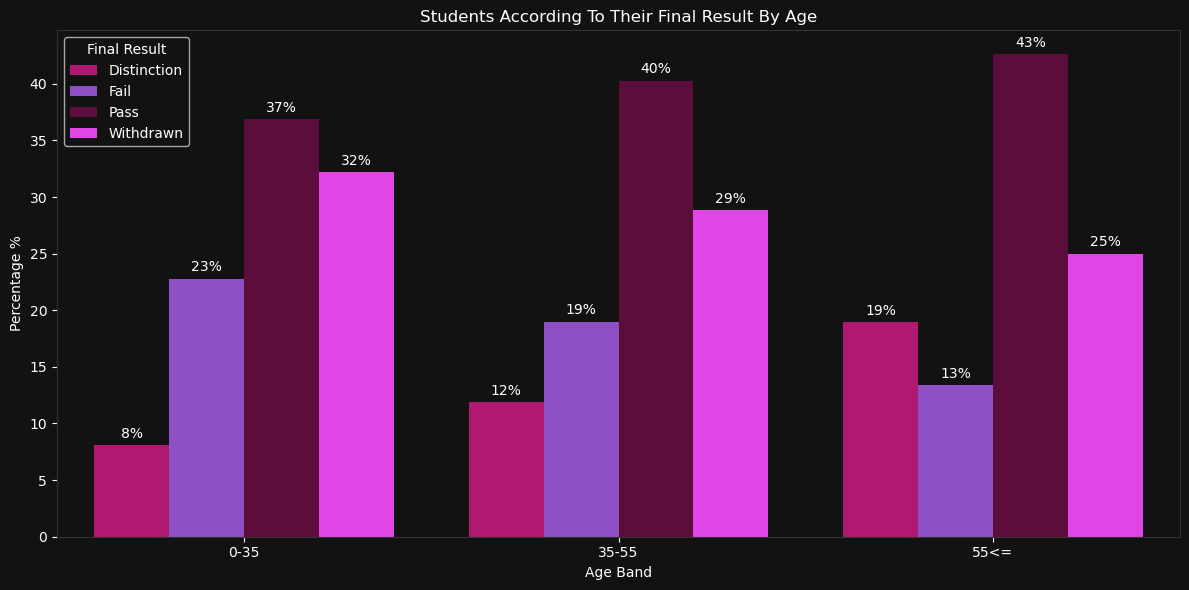

In [12]:
plt.figure(figsize=(12,6))

ax = sns.barplot(
    data=df_ab,
    x='age_band',
    y='percentage',
    hue='final_result',
    palette=["#c90076",'#8e3cd9','#6a003e','#f72cff']
)
plt.title('Students According To Their Final Result By Age')
plt.legend(title='Final Result')
plt.xlabel('Age Band')
plt.ylabel('Percentage %')

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f%%', padding=3, color='white')

plt.tight_layout()
plt.show()

-In this chart, we can see the older a student is means a better performance, normally the oldest people have more experience in academic courses and also some of them have Post Graduate studies, that's why when we see the percentage is better than the other two groups.  
-Nevertheless, it is necessary to consider that the 55<= is the one that has less students due to the proportion that is really small compared with the other two groups.

In [14]:
df1.columns.to_list()

['code_module',
 'code_presentation',
 'id_student',
 'gender',
 'region',
 'highest_education',
 'imd_band',
 'age_band',
 'num_of_prev_attempts',
 'studied_credits',
 'disability',
 'final_result']

In [15]:
df1.disability.unique()

array(['N', 'Y'], dtype=object)

In [16]:
QUERY2 = """
    WITH Countbygender AS (
    SELECT 
        final_result,
        gender,
        COUNT(*) as total_students
    FROM student_db
    GROUP BY final_result, gender
    ),
    TotalBygender AS (
    SELECT 
        gender,
        SUM(total_students) as total_gender
    FROM Countbygender
    GROUP BY gender
    )
    SELECT 
        c.final_result,
        c.gender,
        c.total_students,
        (c.total_students * 100.0 / t.total_gender) as percentage
    FROM Countbygender c
    JOIN TotalBygender t ON c.gender = t.gender
    ORDER BY c.gender, c.final_result;
    """
df_g = pd.read_sql_query(QUERY2, conexion)
print(df_g.head(12))

  final_result gender  total_students  percentage
0  Distinction      F            1394    9.471396
1         Fail      F            3103   21.083028
2         Pass      F            5735   38.965892
3    Withdrawn      F            4486   30.479685
4  Distinction      M            1630    9.118881
5         Fail      M            3949   22.092308
6         Pass      M            6626   37.068531
7    Withdrawn      M            5670   31.720280


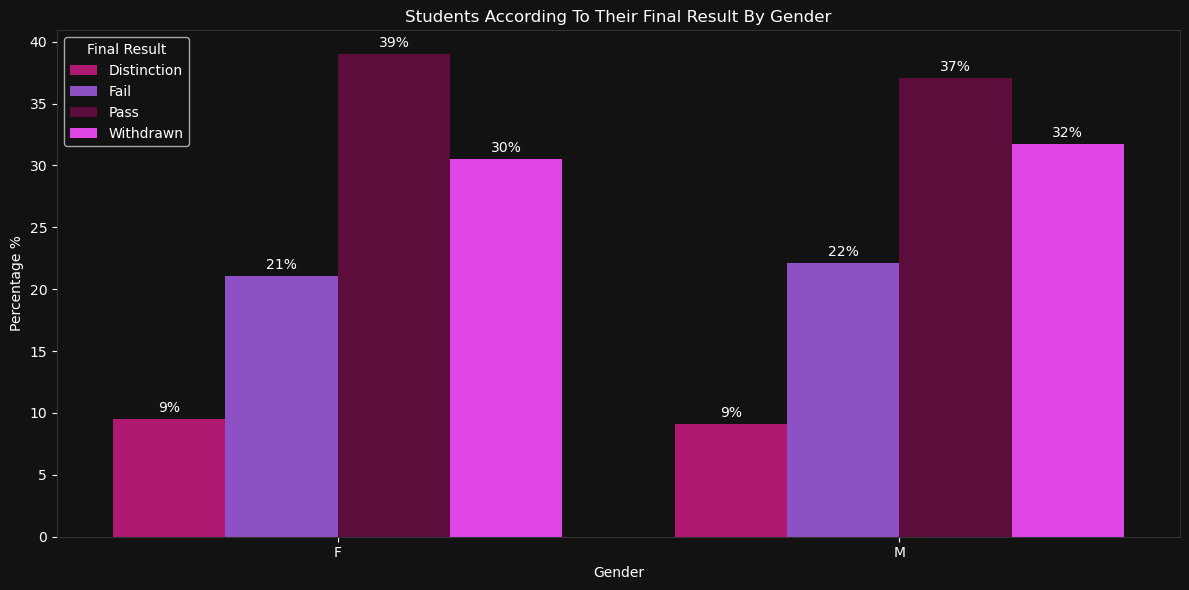

In [17]:
plt.figure(figsize=(12,6))

ax = sns.barplot(
    data=df_g,
    x='gender',
    y='percentage',
    hue='final_result',
    palette=["#c90076",'#8e3cd9','#6a003e','#f72cff']
)
plt.title('Students According To Their Final Result By Gender')
plt.legend(title='Final Result')
plt.xlabel('Gender')
plt.ylabel('Percentage %')

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f%%', padding=3, color='white')

plt.tight_layout()
plt.show()

In this case, we can affirm that the percentage for every category of Final Result is almost the same refering to sex variable.

In [19]:
QUERY3 = """
    WITH Countbydisability AS (
    SELECT 
        final_result,
        disability,
        COUNT(*) as total_students
    FROM student_db
    GROUP BY final_result, disability
    ),
    TotalBydisability AS (
    SELECT 
        disability,
        SUM(total_students) as total_disability
    FROM Countbydisability
    GROUP BY disability
    )
    SELECT 
        c.final_result,
        c.disability,
        c.total_students,
        (c.total_students * 100.0 / t.total_disability) as percentage
    FROM Countbydisability c
    JOIN TotalBydisability t ON c.disability = t.disability
    ORDER BY c.disability, c.final_result;
    """
df_d = pd.read_sql_query(QUERY3, conexion)
print(df_d.head(12))

  final_result disability  total_students  percentage
0  Distinction          N            2801    9.517823
1         Fail          N            6340   21.543376
2         Pass          N           11377   38.659146
3    Withdrawn          N            8911   30.279656
4  Distinction          Y             223    7.048040
5         Fail          Y             712   22.503161
6         Pass          Y             984   31.099874
7    Withdrawn          Y            1245   39.348925


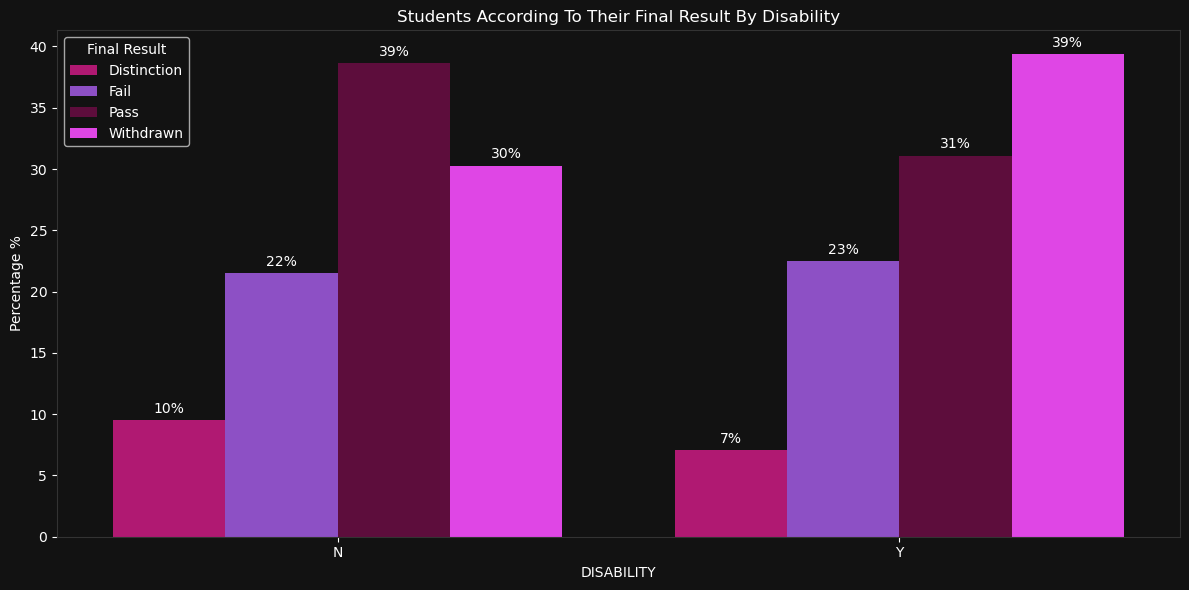

In [20]:
plt.figure(figsize=(12,6))

ax = sns.barplot(
    data=df_d,
    x='disability',
    y='percentage',
    hue='final_result',
    palette=["#c90076",'#8e3cd9','#6a003e','#f72cff']
)
plt.title('Students According To Their Final Result By Disability')
plt.legend(title='Final Result')
plt.xlabel('DISABILITY')
plt.ylabel('Percentage %')

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f%%', padding=3, color='white')

plt.tight_layout()
plt.show()

In the same way, the porcentage for the two first categories are very similar, however, the students identified with disability have the highest rate of Withdrawn.

In [22]:
QUERY5 = """
    UPDATE student_db SET imd_band = '10-20%' WHERE imd_band = '10-20'
"""
conexion.execute(QUERY5)
conexion.commit()

In [23]:
QUERY4 = """
    WITH Countbyimd AS (
    SELECT 
        final_result,
        imd_band,
        COUNT(*) as total_students
    FROM student_db
    WHERE imd_band IS NOT NULL 
        AND imd_band != '?' 
        AND imd_band != ''
    GROUP BY final_result, imd_band
    ),
    TotalByImd AS (
    SELECT 
        imd_band,
        SUM(total_students) as total_imd
    FROM Countbyimd
    GROUP BY imd_band
    )
    SELECT 
        c.final_result,
        c.imd_band,
        c.total_students,
        (c.total_students * 100.0 / t.total_imd) as percentage
    FROM Countbyimd c
    JOIN TotalByImd t ON c.imd_band = t.imd_band
    ORDER BY c.imd_band, c.final_result;
    """
df_imd = pd.read_sql_query(QUERY4, conexion)
print(df_imd.head(60))

   final_result imd_band  total_students  percentage
0   Distinction    0-10%             168    5.073996
1          Fail    0-10%             916   27.665358
2          Pass    0-10%             996   30.081546
3     Withdrawn    0-10%            1231   37.179100
4   Distinction   10-20%             191    5.432309
5          Fail   10-20%             912   25.938567
6          Pass   10-20%            1167   33.191126
7     Withdrawn   10-20%            1246   35.437998
8   Distinction   20-30%             263    7.197592
9          Fail   20-30%             844   23.097975
10         Pass   20-30%            1226   33.552271
11    Withdrawn   20-30%            1321   36.152162
12  Distinction   30-40%             315    8.900819
13         Fail   30-40%             784   22.153151
14         Pass   30-40%            1345   38.005086
15    Withdrawn   30-40%            1095   30.940944
16  Distinction   40-50%             293    8.998771
17         Fail   40-50%             697   21.

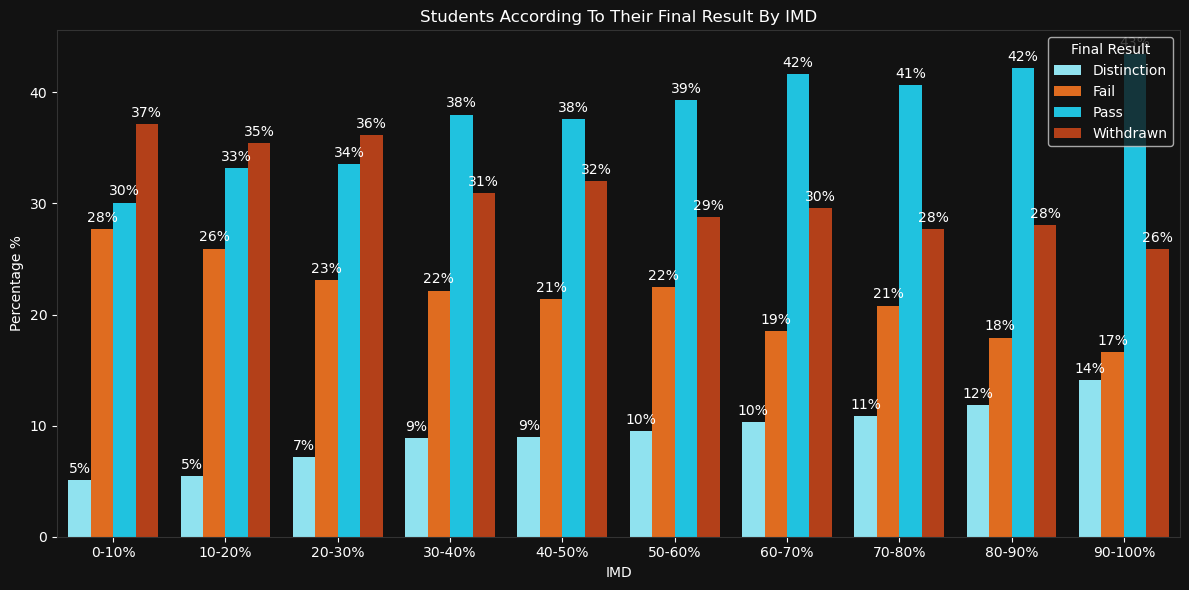

In [24]:
plt.figure(figsize=(12,6))

ax = sns.barplot(
    data=df_imd,
    x='imd_band',
    y='percentage',
    hue='final_result',
    palette=['#80edff', '#ff6600','#00d8ff','#cc3300']
)
plt.title('Students According To Their Final Result By IMD')
plt.legend(title='Final Result')
plt.xlabel('IMD')
plt.ylabel('Percentage %')

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f%%', padding=3, color='white')

plt.tight_layout()
plt.show()

In this graph, it is possible to notice that the more IMD level the rate of Distinction and Pass increase.  
-On the other hand, Fail and Withdrawn decrease irregularly but with a clear trend: people with high IMD level normally finish their study with success more than people with a low IMD level.  
-Moreover, there are key factors that make people desert from a course, such as, more hours for the job, less technological resources.  
Note: Missing location records ('?') were excluded from the IMD analysis to maintain ordinal integrity across socioeconomic bands.

In [26]:
QUERY6 = """
    WITH Countbyprev AS (
    SELECT 
        final_result,
        num_of_prev_attempts,
        COUNT(*) as total_students
    FROM student_db
    GROUP BY final_result, num_of_prev_attempts
    ),
    TotalByprev AS (
    SELECT 
        num_of_prev_attempts,
        SUM(total_students) as total_num_of_prev_attempts
    FROM Countbyprev
    GROUP BY num_of_prev_attempts
    )
    SELECT 
        c.final_result,
        c.num_of_prev_attempts,
        c.total_students,
        (c.total_students * 100.0 / t.total_num_of_prev_attempts) as percentage
    FROM Countbyprev c
    JOIN TotalByprev t ON c.num_of_prev_attempts = t.num_of_prev_attempts
    ORDER BY c.num_of_prev_attempts, c.final_result;
    """
df_n = pd.read_sql_query(QUERY6, conexion)
print(df_n.head(28))

   final_result  num_of_prev_attempts  total_students  percentage
0   Distinction                     0            2857   10.052426
1          Fail                     0            5731   20.164667
2          Pass                     0           11148   39.224517
3     Withdrawn                     0            8685   30.558390
4   Distinction                     1             143    4.334647
5          Fail                     1            1009   30.585026
6          Pass                     1             997   30.221279
7     Withdrawn                     1            1150   34.859048
8   Distinction                     2              22    3.259259
9          Fail                     2             236   34.962963
10         Pass                     2             170   25.185185
11    Withdrawn                     2             247   36.592593
12  Distinction                     3               1    0.704225
13         Fail                     3              57   40.140845
14        

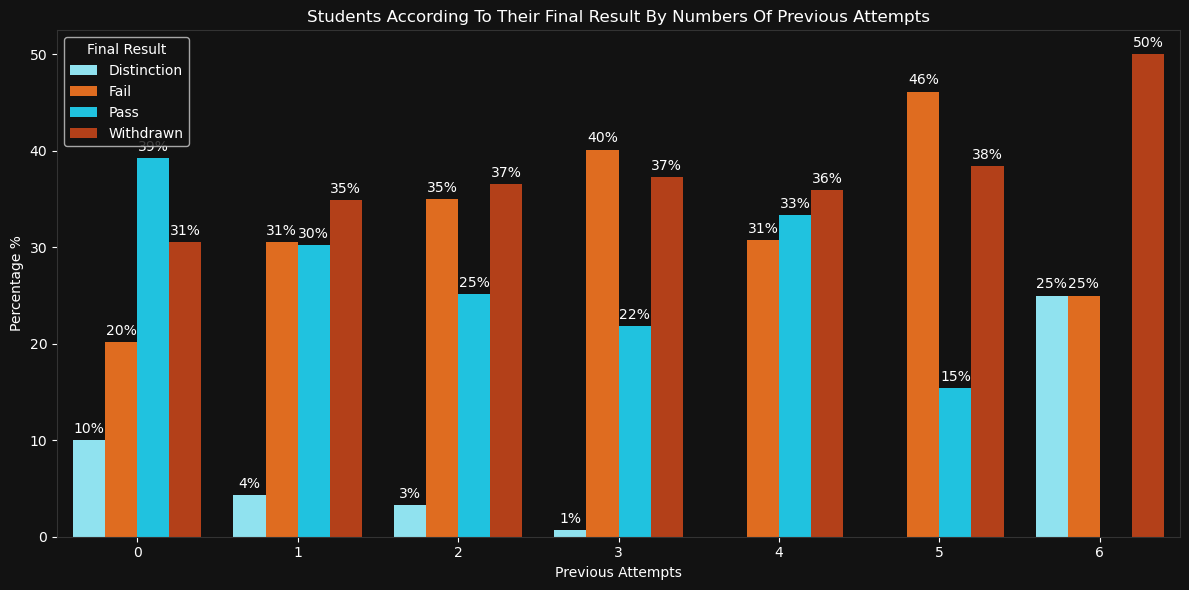

In [27]:
plt.figure(figsize=(12,6))

ax = sns.barplot(
    data=df_n,
    x='num_of_prev_attempts',
    y='percentage',
    hue='final_result',
    palette=['#80edff', '#ff6600','#00d8ff','#cc3300']
)
plt.title('Students According To Their Final Result By Numbers Of Previous Attempts')
plt.legend(title='Final Result')
plt.xlabel('Previous Attempts')
plt.ylabel('Percentage %')

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f%%', padding=3, color='white')

plt.tight_layout()
plt.show()

With this graph, we can notice that the best performances are in the first and second attempt (0 and 1).  
-Withdrawn rate increases with the nummber of attempts, meanwhile the other factores are irregulars.  
-But, in the next graph we'll notice that the proportion of students decrease when the attempts grow, for example, in the 6th attempt we see that the 50% forsake the course, but when we see the data of, the table above and the chart of below, only two students did it.

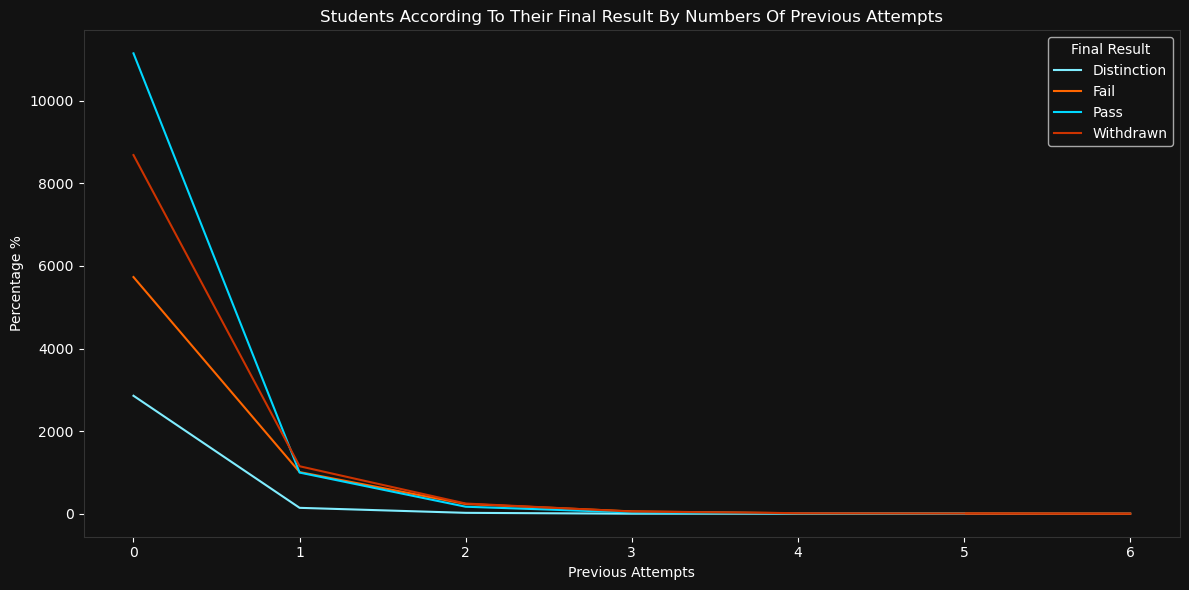

In [29]:
plt.figure(figsize=(12,6))

ax = sns.lineplot(
    data=df_n,
    x='num_of_prev_attempts',
    y='total_students',
    hue='final_result',
    palette=['#80edff', '#ff6600','#00d8ff','#cc3300']
)
plt.title('Students According To Their Final Result By Numbers Of Previous Attempts')
plt.legend(title='Final Result')
plt.xlabel('Previous Attempts')
plt.ylabel('Percentage %')

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f%%', padding=3, color='white')

plt.tight_layout()
plt.show()

In [30]:
df2 = pd.read_csv('studentRegistration.csv')
df2.to_sql('registration', conexion, index=False)

32593

In [31]:
df2.dtypes

code_module            object
code_presentation      object
id_student              int64
date_registration      object
date_unregistration    object
dtype: object

In [32]:
df1.dtypes

code_module             object
code_presentation       object
id_student               int64
gender                  object
region                  object
highest_education       object
imd_band                object
age_band                object
num_of_prev_attempts     int64
studied_credits          int64
disability              object
final_result            object
dtype: object

In [33]:
df2.date_unregistration.tail()

32588      ?
32589      ?
32590      ?
32591    101
32592      ?
Name: date_unregistration, dtype: object

In [34]:
QUERY7 = """
    SELECT s.id_student, s.final_result, r.date_registration, r.date_unregistration
    from student_db s
    JOIN registration r 
    ON s.id_student = r.id_student 
        AND s.code_module = r.code_module 
        AND s.code_presentation = r.code_presentation
    WHERE s.final_result = 'Withdrawn'
    """
df_registration = pd.read_sql_query(QUERY7, conexion)
print(df_registration.head(20))

    id_student final_result date_registration date_unregistration
0        30268    Withdrawn               -92                  12
1        65002    Withdrawn              -180                  96
2        94961    Withdrawn              -170                  72
3       106247    Withdrawn                 5                 175
4       129955    Withdrawn              -197                 135
5       135335    Withdrawn               -29                  30
6       135400    Withdrawn               -32                 144
7       141377    Withdrawn              -110                 129
8       147793    Withdrawn              -138                  58
9       148993    Withdrawn              -174                 158
10      155984    Withdrawn               -64                 191
11      159954    Withdrawn               -46                 123
12      181316    Withdrawn               -39                  60
13      188278    Withdrawn               -57                  60
14      19

In [35]:
df_registration['date_unregistration'] = pd.to_numeric(df_registration['date_unregistration'], errors='coerce')
df_registration = df_registration.dropna(subset=['date_unregistration'])


df_filtrado = df_registration[(df_registration['date_unregistration'] >= -30) & (df_registration['date_unregistration'] <= 300)]

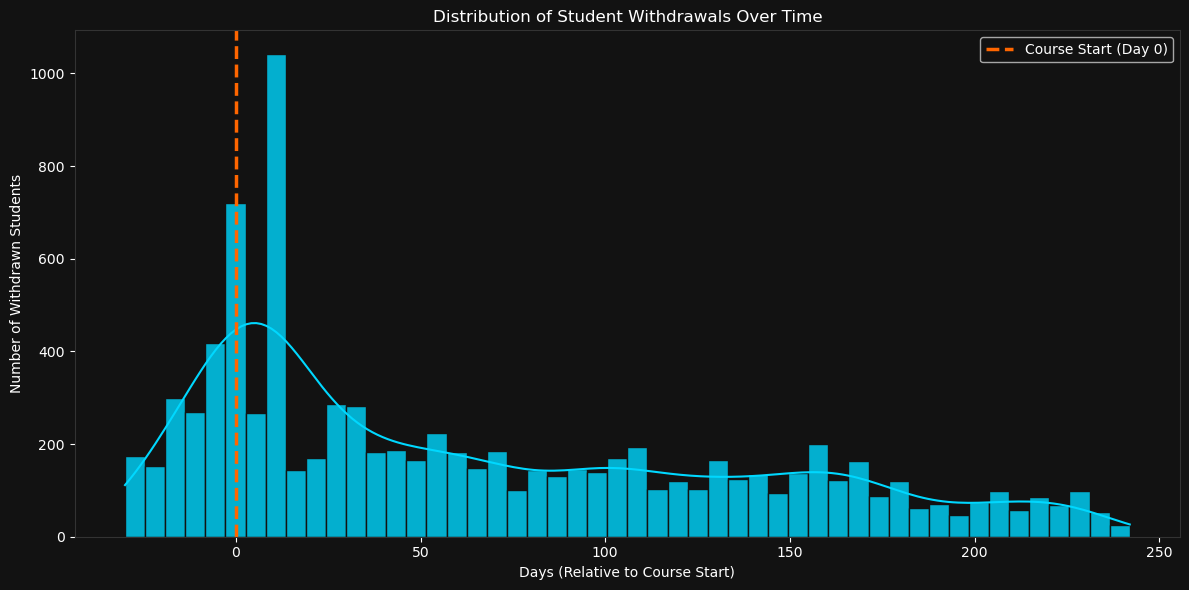

In [36]:
plt.figure(figsize=(12,6))

ax = sns.histplot(
    data=df_filtrado,
    x='date_unregistration',
    kde=True,
    line_kws={'color': '#121212'},
    edgecolor='#121212',
    alpha=0.8,
    bins=50,
)
plt.axvline(x=0, color='#ff6600', linestyle='--', linewidth=2.5, label='Course Start (Day 0)')

plt.title('Distribution of Student Withdrawals Over Time')
plt.xlabel('Days (Relative to Course Start)')
plt.ylabel('Number of Withdrawn Students')
plt.legend()

plt.tight_layout()
plt.show()

The strategies of rettention and tutorials must be focused on the progress of 'Onboarding' (previous days for starting) and during the first two weeks of classes. So, to try saving students in the middle of semester is too late because the critical peak is on the first days of the semester.  
Although, we can see that people desert the course the next weeks with some bumps.

In [38]:
df3 = pd.read_csv('studentAssessment.csv')
df3.to_sql('student_assessment', conexion, index=False)
df4 = pd.read_csv('Assessments.csv')
df4.to_sql('assessment', conexion, index=False)

206

In [39]:
len(df3)

173912

In [40]:
df1.columns

Index(['code_module', 'code_presentation', 'id_student', 'gender', 'region',
       'highest_education', 'imd_band', 'age_band', 'num_of_prev_attempts',
       'studied_credits', 'disability', 'final_result'],
      dtype='object')

In [41]:
df3.columns

Index(['id_assessment', 'id_student', 'date_submitted', 'is_banked', 'score'], dtype='object')

In [42]:
df4.columns

Index(['code_module', 'code_presentation', 'id_assessment', 'assessment_type',
       'date', 'weight'],
      dtype='object')

In this point, we'll analyze the relationship between the Date, Date Submitted and the Score of the Assessment.  
Do students that deliver lately their assessment score less points?

In [44]:
QUERY8 = """
    SELECT a.date, sa.date_submitted, sa.score, s.final_result
    FROM assessment AS a
    
    JOIN student_assessment AS sa
        ON a.id_assessment = sa.id_assessment
    JOIN student_db AS s
        ON sa.id_student = s.id_student
        WHERE a.date IS NOT NULL
"""
df_assessment = pd.read_sql_query(QUERY8, conexion)
print(df_assessment.head(40))

   date  date_submitted score final_result
0    19              18    78         Pass
1    19              22    70         Pass
2    19              17    72         Pass
3    19              26    69         Pass
4    19              19    79         Pass
5    19              20    70         Pass
6    19              18    72         Pass
7    19              19    72         Pass
8    19               9    71         Pass
9    19              18    68         Pass
10   19              19    73         Pass
11   19              18    67         Pass
12   19              17    73         Pass
13   19              19    83         Pass
14   19              17    66         Fail
15   19              17    66    Withdrawn
16   19              19    59         Pass
17   19              19    82         Pass
18   19              22    60         Fail
19   19              18    67         Pass
20   19              18    73         Pass
21   19              21    75         Pass
22   19    

In [45]:
df_assessment['date'] = pd.to_numeric(df_assessment['date'], errors='coerce')
df_assessment['date'] = df_assessment['date'].fillna(df_assessment['date'].mean())
df_assessment['date'] = df_assessment['date'].astype(int)
df_assessment["diference"] = df_assessment['date'] - df_assessment['date_submitted']
df_assessment.head(20)

,date,date_submitted,score,final_result,diference
0,19,18,78,Pass,1
1,19,22,70,Pass,-3
2,19,17,72,Pass,2
3,19,26,69,Pass,-7
4,19,19,79,Pass,0
5,19,20,70,Pass,-1
6,19,18,72,Pass,1
7,19,19,72,Pass,0
8,19,9,71,Pass,10
9,19,18,68,Pass,1


In [46]:
df_assessment['score'] = pd.to_numeric(df_assessment['score'], errors='coerce')
df_assessment['score'] = df_assessment['score'].fillna(0)

In [47]:
df_assessment['score'] = df_assessment['score'].astype(int)

In [48]:
df_assessment['score'].unique()

array([ 78,  70,  72,  69,  79,  71,  68,  73,  67,  83,  66,  59,  82,
        60,  75,  74,  62,  63,  84,  80,  76,  85,  57,  81,  87,  77,
        45,  65,  61,  52,  54,  51,  88,  58,  64,  55,  38,  91,  47,
        89,  36,  86,  49,  53,  39,   0,  90,  50,  56,  30,  11,  40,
        94,  48,  46,  42,  18,  37,  28,  33,  95,  35,  44,  25,  41,
        15,  34,  43,  93,  32,  92,  98,  19,  27,  24,  29,  20, 100,
        97,  23,  99,  10,   5,  13,  26,  22,   8,  12,  16,   9,  96,
        14,  21,  17,  31,   6,   1,   7,   4,   2,   3])

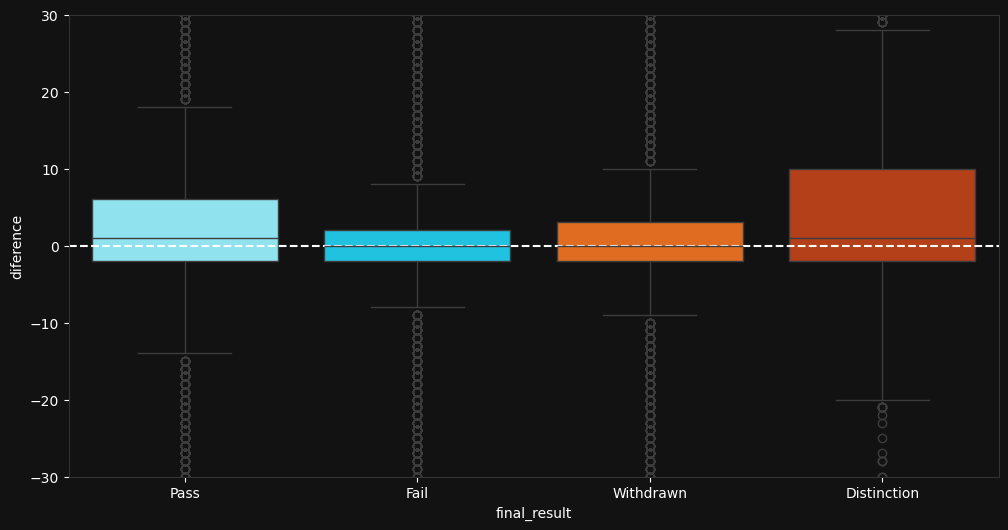

In [49]:
plt.figure(figsize=(12,6))
sns.boxplot(
    data=df_assessment,
    x="final_result",
    y="diference",
    hue="final_result",
    legend=False,
    palette=['#80edff', '#00d8ff', '#ff6600', '#cc3300']
)
plt.axhline(y=0, color='white', linestyle='--', linewidth=1.5)
plt.ylim(-30, 30)
plt.show()

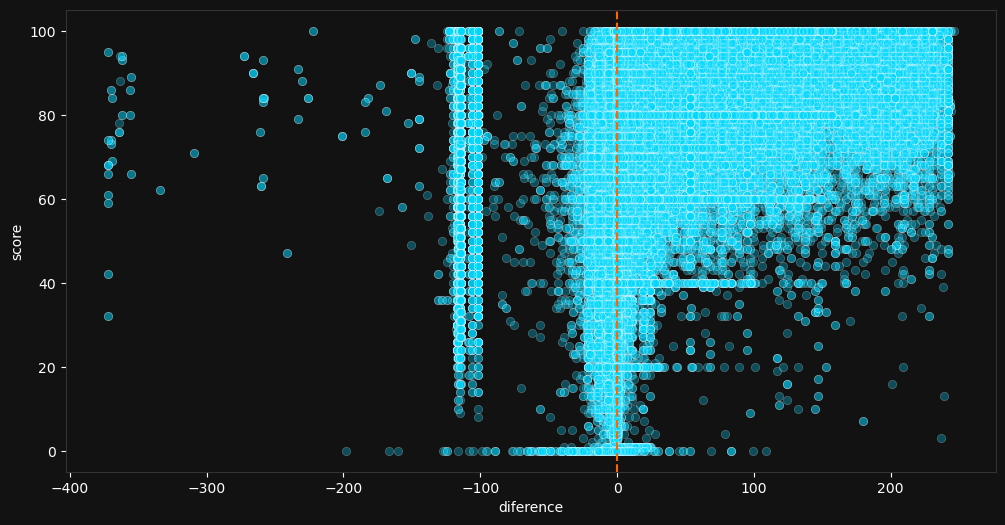

In [50]:
plt.figure(figsize=(12,6))
sns.scatterplot(
    data=df_assessment,
    x="diference",
    y="score",
    alpha=0.3,
    color='#00d8ff'
)
plt.axvline(x=0, color='#ff6600', linestyle='--', label='Deadline')
#plt.axvline(x=0, color='#ff6600', linestyle='--', linewidth=2.5, label='Course Start (Day 0)')
plt.show()

Human behavior never forms perfect lines, so this pattern indicates automated registers from the system, submitted scores in block by the teacher or preload assessments. Also, some students submitted their assessment lately, but it does not mean they will obtain a low score. 

Now, it is the time for answering the next question:  
Does the volume of clicks on the first two or three weeks of the course allow to predict if a students will pass or fail/desert?

In [94]:
df5 = pd.read_csv('studentVle.csv')
df5.to_sql('student_v', conexion, index=False)

10655280

In [96]:
df5.columns.tolist()

['code_module',
 'code_presentation',
 'id_student',
 'id_site',
 'date',
 'sum_click']

In [100]:
df1.dtypes

code_module             object
code_presentation       object
id_student               int64
gender                  object
region                  object
highest_education       object
imd_band                object
age_band                object
num_of_prev_attempts     int64
studied_credits          int64
disability              object
final_result            object
dtype: object

In [98]:
df5.dtypes

code_module          object
code_presentation    object
id_student            int64
id_site               int64
date                  int64
sum_click             int64
dtype: object

In [106]:
QUERY9 = """
    SELECT sv.sum_click, sv.date, s.final_result
    FROM student_db AS s
    JOIN student_v AS sv
    ON sv.id_student = s.id_student
    WHERE sv.date IS NOT NULL AND sv.sum_click IS NOT NULL
"""
df_vl = pd.read_sql_query(QUERY9, conexion)
print(df_vl.tail(40))

          sum_click  date final_result
13006535          2   268  Distinction
13006536          1   268         Pass
13006537          1   268         Pass
13006538          1   268         Pass
13006539          2   268         Pass
13006540          1   268         Pass
13006541          1   268         Pass
13006542          1   268  Distinction
13006543          1   268         Pass
13006544          1   268         Pass
13006545          1   268         Pass
13006546          1   268  Distinction
13006547          2   268         Pass
13006548          1   268         Pass
13006549          2   268         Pass
13006550          2   268         Pass
13006551          2   268         Pass
13006552          2   268         Pass
13006553          3   268         Fail
13006554          2   269         Fail
13006555          1   269         Pass
13006556          1   269         Pass
13006557          1   269         Pass
13006558          2   269  Distinction
13006559          1   269

In [108]:
df_vl.dtypes

sum_click        int64
date             int64
final_result    object
dtype: object

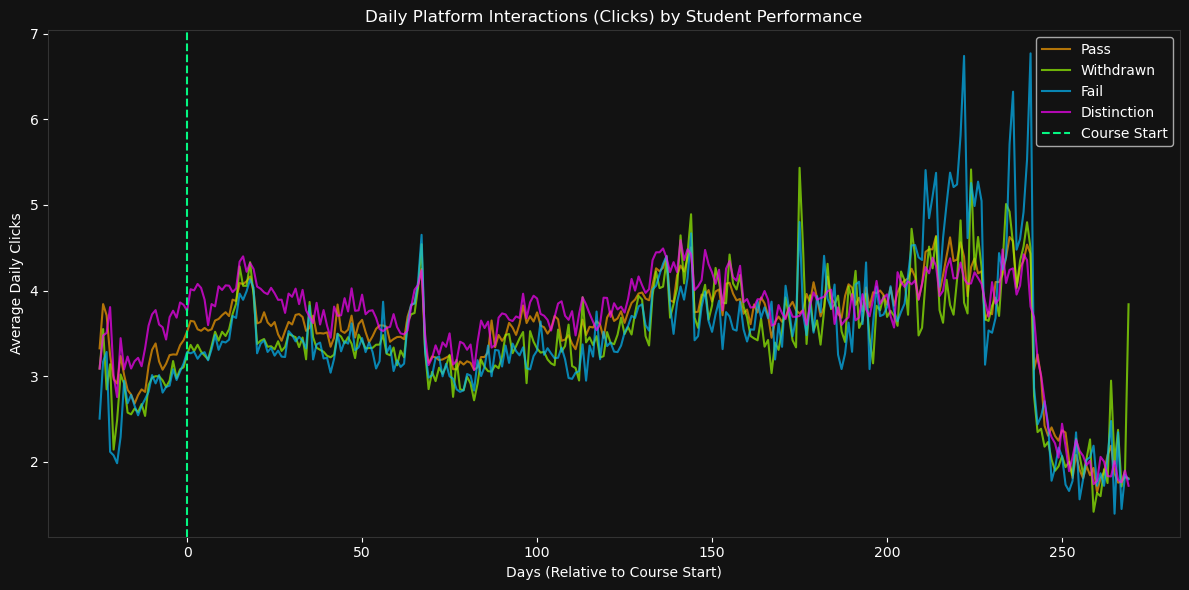

In [122]:
plt.figure(figsize=(12,6))
sns.lineplot(
    data=df_vl,
    x='date',
    y='sum_click',
    hue='final_result',
    palette=['#f79e05', '#96f705', '#05b7f7', '#f705f7'],
    alpha=0.7,
    errorbar=None,
)
plt.axvline(x=0, color='#05f782', linestyle='--', label='Course Start')
plt.title('Daily Platform Interactions (Clicks) by Student Performance')
plt.xlabel('Days (Relative to Course Start)')
plt.ylabel('Average Daily Clicks')
plt.legend()

plt.tight_layout()
plt.show()

With this chart, it is possible to conclude that students that were successful during the course (Pass and Distinction) interact with the platform the first weeks more than students that fail and desert, even before the course starts, this explains why they had a good performance, they interact with the content and assessments of the course. However, the difference is not so long when comparing these two groups of students, but that's curious.  
Moreover, we can see that in some weeks the students interact with the platform almost equally, this could be because of deadlines.  
Finally, from day 200 we can notice that mostly students that failed the course interact with the platform more than the other students, this might be because they are trying to "make a comeback" in the semester, but this didn't happened. In the same way, some students that deserted interacted with the platform the last days more than the other groups of students.